Assignment 3

**Team:** `Gerlind`
**Mitglieder:** `Erlind Sejdiu`, `Gleb Janickij`


In [3]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.tensorboard import SummaryWriter

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps") # Für Macs
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print(f"PyTorch {torch.__version__} | GPU-Gerät: {DEVICE}")

PyTorch 2.14.1+cu130 | GPU-Gerät: cuda


In [4]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

trainset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform)
testset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform)

classes = ("plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

def make_loaders(batch_size):
    trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
    testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)
    return trainloader, testloader

print(f"Train: {len(trainset)} Bilder | Test: {len(testset)} Bilder")

Train: 50000 Bilder | Test: 10000 Bilder


In [5]:
writer = SummaryWriter("runs/assignment3")


def sync(device):
    if device.type == "mps":
        torch.mps.synchronize()
    elif device.type == "cuda":
        torch.cuda.synchronize()


def train(net, trainloader, optimizer, epochs, device, tag=None, log_every=200):
    criterion = nn.CrossEntropyLoss()
    net.to(device)
    net.train()
    step = 0
    sync(device)
    start = time.perf_counter()
    for epoch in range(epochs):
        running_loss = 0.0
        for i, (inputs, labels) in enumerate(trainloader):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(net(inputs), labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            step += 1
            if (i + 1) % log_every == 0:
                avg = running_loss / log_every
                if tag is not None:
                    writer.add_scalar(f"Loss/train/{tag}", avg, step)
                print(f"[Epoche {epoch + 1}, Batch {i + 1:5d}] Loss: {avg:.3f}")
                running_loss = 0.0
    sync(device)
    duration = time.perf_counter() - start
    print(f"Training fertig in {duration:.1f} s")
    return duration


@torch.no_grad()
def top1_accuracy(net, testloader, device):
    net.to(device).eval()
    correct = total = 0
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        predicted = net(images).argmax(dim=1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    return 100 * correct / total

## Aufgabe 1

In [6]:
class TutorialNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)


tut_trainloader, tut_testloader = make_loaders(batch_size=4)

tutorial_net = TutorialNet()
tut_optimizer = optim.SGD(tutorial_net.parameters(), lr=0.001, momentum=0.9)
train(tutorial_net, tut_trainloader, tut_optimizer, epochs=2, device=DEVICE, tag="tutorial_net", log_every=2000)

print(f"Top-1-Test-Accuracy (Tutorial-Netz): {top1_accuracy(tutorial_net, tut_testloader, DEVICE):.2f} %")

[Epoche 1, Batch  2000] Loss: 2.169
[Epoche 1, Batch  4000] Loss: 1.786
[Epoche 1, Batch  6000] Loss: 1.655
[Epoche 1, Batch  8000] Loss: 1.553
[Epoche 1, Batch 10000] Loss: 1.518
[Epoche 1, Batch 12000] Loss: 1.433
[Epoche 2, Batch  2000] Loss: 1.362
[Epoche 2, Batch  4000] Loss: 1.356
[Epoche 2, Batch  6000] Loss: 1.305
[Epoche 2, Batch  8000] Loss: 1.281
[Epoche 2, Batch 10000] Loss: 1.319
[Epoche 2, Batch 12000] Loss: 1.238
Training fertig in 52.5 s
Top-1-Test-Accuracy (Tutorial-Netz): 56.23 %


## Aufgabe 2

In [7]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 8, 3, padding=1)    # 2.1
        self.conv2 = nn.Conv2d(8, 16, 3, padding=1)   # 2.2
        self.pool = nn.MaxPool2d(2, 2)                # 2.3 und 2.6
        self.conv3 = nn.Conv2d(16, 32, 3, padding=1)  # 2.4
        self.conv4 = nn.Conv2d(32, 64, 3, padding=1)  # 2.5
        self.fc1 = nn.Linear(64 * 8 * 8, 4096)        # 2.7
        self.fc2 = nn.Linear(4096, 1000)
        self.fc3 = nn.Linear(1000, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.relu(self.conv2(x))
        x = self.pool(x)
        x = F.relu(self.conv3(x))
        x = F.relu(self.conv4(x))
        x = self.pool(x)
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)  # Logits


BATCH_SIZE = 64
EPOCHS = 10
LR = 0.001

trainloader, testloader = make_loaders(batch_size=BATCH_SIZE)

net = Net()
print(net)
print(f"Parameter: {sum(p.numel() for p in net.parameters()):,}")

Net(
  (conv1): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=4096, out_features=4096, bias=True)
  (fc2): Linear(in_features=4096, out_features=1000, bias=True)
  (fc3): Linear(in_features=1000, out_features=10, bias=True)
)
Parameter: 20,912,850


In [8]:
optimizer = optim.Adam(net.parameters(), lr=LR)
train(net, trainloader, optimizer, epochs=EPOCHS, device=DEVICE, tag="net", log_every=100)

print(f"Top-1-Test-Accuracy (neues Netz): {top1_accuracy(net, testloader, DEVICE):.2f} %")

[Epoche 1, Batch   100] Loss: 2.084
[Epoche 1, Batch   200] Loss: 1.671
[Epoche 1, Batch   300] Loss: 1.552
[Epoche 1, Batch   400] Loss: 1.409
[Epoche 1, Batch   500] Loss: 1.371
[Epoche 1, Batch   600] Loss: 1.277
[Epoche 1, Batch   700] Loss: 1.259
[Epoche 2, Batch   100] Loss: 1.097
[Epoche 2, Batch   200] Loss: 1.097
[Epoche 2, Batch   300] Loss: 1.044
[Epoche 2, Batch   400] Loss: 1.015
[Epoche 2, Batch   500] Loss: 1.014
[Epoche 2, Batch   600] Loss: 0.977
[Epoche 2, Batch   700] Loss: 0.943
[Epoche 3, Batch   100] Loss: 0.769
[Epoche 3, Batch   200] Loss: 0.782
[Epoche 3, Batch   300] Loss: 0.780
[Epoche 3, Batch   400] Loss: 0.801
[Epoche 3, Batch   500] Loss: 0.784
[Epoche 3, Batch   600] Loss: 0.726
[Epoche 3, Batch   700] Loss: 0.733
[Epoche 4, Batch   100] Loss: 0.569
[Epoche 4, Batch   200] Loss: 0.572
[Epoche 4, Batch   300] Loss: 0.566
[Epoche 4, Batch   400] Loss: 0.550
[Epoche 4, Batch   500] Loss: 0.548
[Epoche 4, Batch   600] Loss: 0.567
[Epoche 4, Batch   700] Loss

## Aufgabe 3

In [12]:
BENCH_EPOCHS = 1
times = {}
bench_devices = [torch.device("cpu")] + ([DEVICE] if DEVICE.type != "cpu" else [])

for device in bench_devices:
    torch.manual_seed(SEED)
    bench_net = Net()
    bench_opt = optim.Adam(bench_net.parameters(), lr=LR)
    print(f"--- {device} ---")
    times[device.type] = train(bench_net, trainloader, bench_opt, epochs=BENCH_EPOCHS, device=device, log_every=10**9)

for name, t in times.items():
    print(f"{name.upper():>4}: {t:7.1f} s für {BENCH_EPOCHS} Epoche(n)")
if DEVICE.type != "cpu":
    print(f"Speedup GPU ({DEVICE.type.upper()}) gegenüber CPU: {times['cpu'] / times[DEVICE.type]:.1f}x")

--- cpu ---
Training fertig in 84.2 s
--- cuda ---
Training fertig in 9.1 s
 CPU:    84.2 s für 1 Epoche(n)
CUDA:     9.1 s für 1 Epoche(n)
Speedup GPU (CUDA) gegenüber CPU: 9.3x


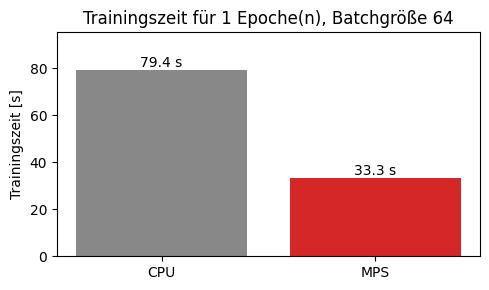

In [13]:
fig, ax = plt.subplots(figsize=(5, 3))
names = [n.upper() for n in times]
ax.bar(names, list(times.values()), color=["#888888", "#d62728"][: len(times)])
ax.set_ylabel("Trainingszeit [s]")
ax.set_ylim(0, max(times.values()) * 1.2)
ax.set_title(f"Trainingszeit für {BENCH_EPOCHS} Epoche(n), Batchgröße {BATCH_SIZE}")
for i, t in enumerate(times.values()):
    ax.text(i, t, f"{t:.1f} s", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## Aufgabe 4

In [14]:
import warnings

example_images, _ = next(iter(trainloader))
net.to("cpu").eval()
with warnings.catch_warnings():
    warnings.simplefilter("ignore", FutureWarning)
    writer.add_graph(net, example_images)
net.to(DEVICE)
writer.flush()
print("Graph und Loss-Kurven in runs/assignment3 geschrieben")

Graph und Loss-Kurven in runs/assignment3 geschrieben


## Aufgabe 5

In [15]:
@torch.no_grad()
def topk_accuracy(net, testloader, device, k=3):
    net.to(device).eval()
    correct = total = 0
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        topk = net(images).topk(k, dim=1).indices          # (B, k)
        correct += (topk == labels.unsqueeze(1)).any(dim=1).sum().item()
        total += labels.size(0)
    return 100 * correct / total


top3 = topk_accuracy(net, testloader, DEVICE, k=3)
top1 = top1_accuracy(net, testloader, DEVICE)
print(f"Top-1-Test-Accuracy: {top1:.2f} %")
print(f"Top-3-Test-Accuracy: {top3:.2f} %")

Top-1-Test-Accuracy: 71.55 %
Top-3-Test-Accuracy: 91.39 %


## Aufgabe 6

In [11]:
@torch.no_grad()
def collect_top3_errors(net, testloader, device):
    net.to(device).eval()
    errors = []
    offset = 0
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)
        probs = F.softmax(net(images), dim=1)
        top_p, top_i = probs.topk(3, dim=1)
        miss = ~(top_i == labels.unsqueeze(1)).any(dim=1)
        for j in miss.nonzero(as_tuple=True)[0].tolist():
            errors.append((offset + j, labels[j].item(), top_i[j].tolist(), top_p[j].tolist()))
        offset += labels.size(0)
    return errors


errors = collect_top3_errors(net, testloader, DEVICE)
print(f"Top-3-Fehler im Testset: {len(errors)} von {len(testset)}")

random.seed(SEED)
samples = random.sample(errors, 5)

Top-3-Fehler im Testset: 865 von 10000


NameError: name 'samples' is not defined

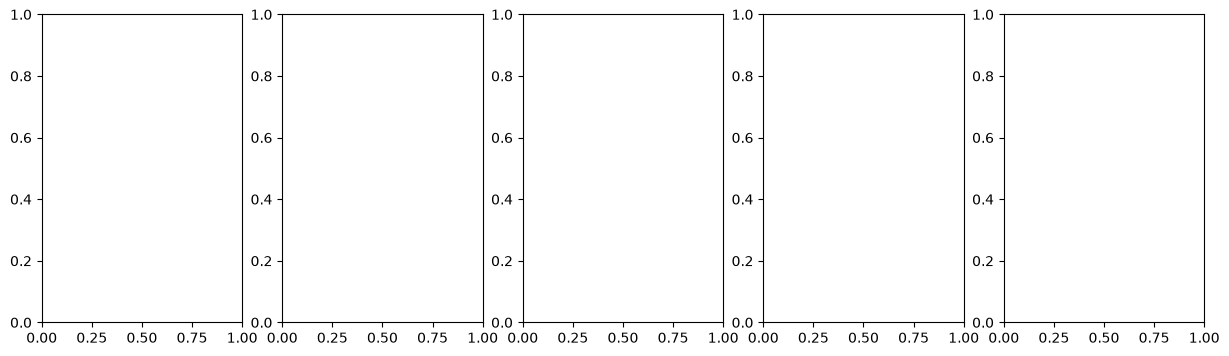

In [10]:
def unnormalize(img):
    return (img * 0.5 + 0.5).clamp(0, 1)  # [-1, 1] -> [0, 1]


fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for ax, (idx, true_label, top_i, top_p) in zip(axes, samples):
    img, _ = testset[idx]
    ax.imshow(unnormalize(img).permute(1, 2, 0).numpy())
    preds = "\n".join(f"{classes[c]} ({p:.0%})" for c, p in zip(top_i, top_p))
    ax.set_title(f"wahr: {classes[true_label]}\nTop-3:\n{preds}", fontsize=10)
    ax.axis("off")
plt.tight_layout()

writer.add_figure("Top-3-Fehler/Beispiele", fig, close=False)

imgs = torch.stack([unnormalize(testset[idx][0]) for idx, *_ in samples])
writer.add_images("Top-3-Fehler/Bilder", imgs)
for n, (idx, true_label, top_i, top_p) in enumerate(samples):
    preds = ", ".join(f"{classes[c]} ({p:.1%})" for c, p in zip(top_i, top_p))
    writer.add_text(f"Top-3-Fehler/Fehler_{n + 1}", f"Testbild #{idx} | wahr: {classes[true_label]} | Top-3: {preds}")
writer.flush()

plt.show()

## Aufgabe 7

In [18]:
writer.close()

In [19]:
%load_ext tensorboard
%tensorboard --logdir runs

Reusing TensorBoard on port 6006 (pid 34585), started 2 days, 5:09:39 ago. (Use '!kill 34585' to kill it.)